# 05 - Model Development, Evaluation & Risk Scoring

Trains the three models agreed on for this project (Logistic Regression
as an interpretable baseline, a Decision Tree, and a Random Forest), plus
an untuned XGBoost as a fourth candidate, compares them properly, and turns
the winning model's output into an actionable risk score. Notebook 06
tunes the shortlist and fixes the decision threshold.

In [1]:
import sys, os, json
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve

from features import FEATURE_COLUMNS, TARGET_COLUMN
from modeling import (
    stratified_split, time_based_split, build_models, evaluate,
    risk_bucket, top_feature_names, NUMERIC, CATEGORICAL,
)
from prediction import explain_order

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
CHART_DIR = "../dashboard/charts"
os.makedirs(CHART_DIR, exist_ok=True)

df = pd.read_csv("../data/processed/ontime_model_ready.csv", parse_dates=["order_purchase_timestamp"])
print("Base delay rate:", df[TARGET_COLUMN].mean().round(4))

Base delay rate: 0.0811


## Train / test split
A stratified random split is used as the headline evaluation (the
standard approach for this kind of coursework). A time-based split is
also tried further down purely as a robustness check.

In [2]:
train_df, test_df = stratified_split(df)
X_train, y_train = train_df[FEATURE_COLUMNS], train_df[TARGET_COLUMN]
X_test, y_test = test_df[FEATURE_COLUMNS], test_df[TARGET_COLUMN]
print(f"Train: {len(train_df):,}  Test: {len(test_df):,}")

Train: 77,176  Test: 19,294


## Train all three models

In [3]:
models = build_models()
results = {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    results[name] = evaluate(pipe, X_test, y_test)

comparison = pd.DataFrame({
    name: {k: v for k, v in res.items() if k in ("precision", "recall", "f1", "roc_auc")}
    for name, res in results.items()
}).T.round(3)
comparison

,precision,recall,f1,roc_auc
logistic_regression,0.143,0.655,0.235,0.710
decision_tree,0.202,0.643,0.308,0.759
random_forest,0.236,0.557,0.331,0.772
xgboost,0.600,0.107,0.182,0.808


## Why accuracy alone would be misleading here
Only ~8% of orders in this dataset actually run late. A model that
predicts "always on time" would score ~92% accuracy while catching
zero real risk cases - which is exactly why precision/recall/F1/ROC-AUC
are reported instead of a single accuracy number.

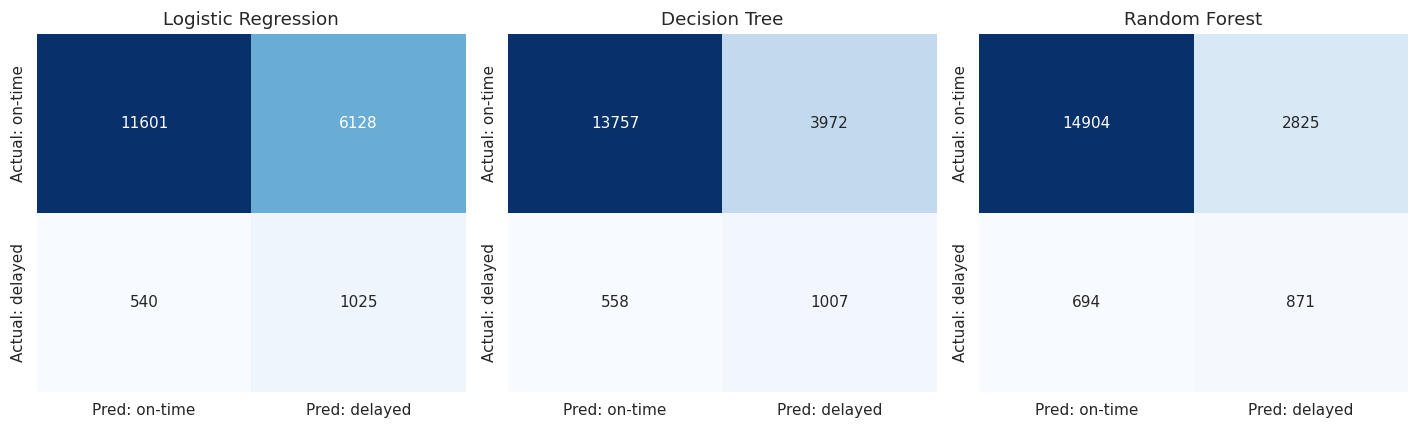

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, res) in zip(axes, results.items()):
    sns.heatmap(res["confusion_matrix"], annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Pred: on-time", "Pred: delayed"],
                yticklabels=["Actual: on-time", "Actual: delayed"], cbar=False)
    ax.set_title(name.replace("_", " ").title())
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/08_confusion_matrices.png")
plt.show()

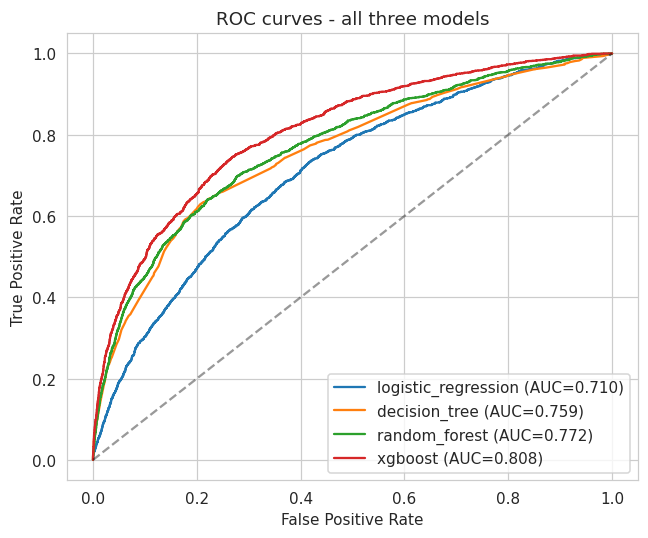

In [5]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, res in results.items():
    fpr, tpr, _ = roc_curve(y_test, res["proba"])
    ax.plot(fpr, tpr, label=f"{name} (AUC={res['roc_auc']:.3f})")
ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC curves - all three models")
ax.legend()
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/09_roc_curves.png")
plt.show()

## Selecting the model
XGBoost has the highest ROC-AUC, so it is selected on ranking quality.
At the default 0.5 threshold, though, this untuned version is very
conservative (high precision, very low recall), because it was fit
without class weighting. Random Forest has the best F1 here. Both points
are picked up in notebook 06, which adds class balancing, tunes the
hyperparameters and chooses the threshold properly.

In [6]:
best_name = comparison["roc_auc"].idxmax()
best_pipe = models[best_name]
print("Selected model:", best_name)
comparison.loc[[best_name]]

Selected model: xgboost


,precision,recall,f1,roc_auc
xgboost,0.6,0.107,0.182,0.808


## Feature importance (selected model)

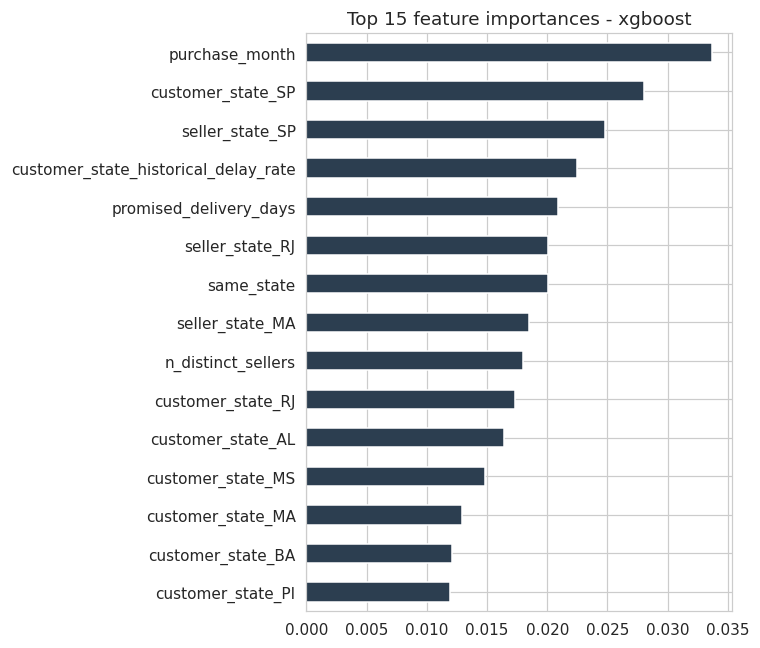

In [7]:
clf = best_pipe.named_steps["clf"]
pre = best_pipe.named_steps["pre"]
names = top_feature_names(pre)
importances = pd.Series(clf.feature_importances_, index=names).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 6))
importances.head(15).sort_values().plot.barh(ax=ax, color="#2c3e50")
ax.set_title(f"Top 15 feature importances - {best_name}")
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/10_feature_importance.png")
plt.show()

Timing (month of purchase), the region's and seller's *historical* delay
rates, shipping distance and the promised delivery window carry most of the
signal. This matches the EDA: risk is concentrated in particular periods,
routes and sellers rather than spread evenly.

## Robustness check: a strict time-based split
Training on earlier orders and testing only on later ones is a harder,
more realistic test - and it exposes a real limitation.

In [8]:
tr2, te2 = time_based_split(df)
rf_time = build_models()["random_forest"]
rf_time.fit(tr2[FEATURE_COLUMNS], tr2[TARGET_COLUMN])
res_time = evaluate(rf_time, te2[FEATURE_COLUMNS], te2[TARGET_COLUMN])
print(f"Random Forest, time-based split: ROC-AUC = {res_time['roc_auc']:.3f}  "
      f"(vs. {results['random_forest']['roc_auc']:.3f} on the random split)")

Random Forest, time-based split: ROC-AUC = 0.479  (vs. 0.772 on the random split)


The drop is sharp. Looking back at notebook 03's monthly delay-rate
chart explains why: the training window (up to mid-2018) includes the
Nov-2017 and Feb/Mar-2018 delay spikes, while the held-out test window
happens to sit in a comparatively calm period. The model partly learned
"this was a rough patch" rather than durable, transferable risk drivers.
**This is flagged in the report as a real limitation**: a production
version of OnTime would need periodic retraining, not a train-once model.

## Turning probabilities into an operational risk score

In [9]:
test_out = test_df.copy()
test_out["delay_probability"] = results[best_name]["proba"]
test_out["risk_level"] = test_out["delay_probability"].apply(risk_bucket)
test_out["risk_level"].value_counts()

risk_level
LOW         18311
MEDIUM        842
HIGH          130
CRITICAL       11
Name: count, dtype: int64

/tmp/ipykernel_255/2528905601.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, palette=colors, ax=ax)


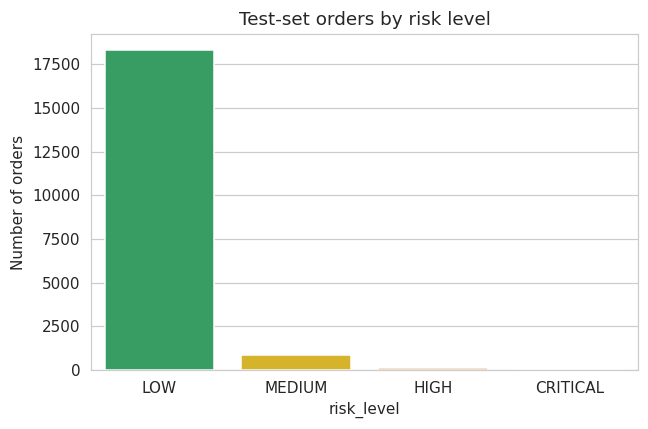

LOW       n=18311  actual delay rate=6.1%
MEDIUM    n=  842  actual delay rate=40.9%
HIGH      n=  130  actual delay rate=68.5%
CRITICAL  n=   11  actual delay rate=90.9%


In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
order = ["LOW", "MEDIUM", "HIGH", "CRITICAL"]
counts = test_out["risk_level"].value_counts().reindex(order)
colors = ["#27ae60", "#f1c40f", "#e67e22", "#c0392b"]
sns.barplot(x=counts.index, y=counts.values, palette=colors, ax=ax)
ax.set_title("Test-set orders by risk level")
ax.set_ylabel("Number of orders")
plt.tight_layout()
plt.savefig(f"{CHART_DIR}/11_risk_level_distribution.png")
plt.show()

for level in order:
    subset = test_out[test_out["risk_level"] == level]
    if len(subset):
        print(f"{level:9s} n={len(subset):5d}  actual delay rate={subset[TARGET_COLUMN].mean():.1%}")

The risk bands track the actual outcome cleanly - CRITICAL-flagged
orders really do run late far more often than LOW-flagged ones, which
is the whole point of an early-warning system: it doesn't need to be
perfect, it needs to correctly prioritise attention.

## Per-order explanation demo

In [11]:
sample_ids = (
    test_out.sort_values("delay_probability", ascending=False)
    .head(5)["order_id"].tolist()
)
for oid in sample_ids:
    row = test_df[test_df["order_id"] == oid]
    proba, level, reasons = explain_order(best_pipe, row, FEATURE_COLUMNS)
    print(f"\nOrder {oid[:10]}...  risk={proba:.0%}  level={level}")
    for feat, val, label in reasons:
        print(f"   - {label} (value: {val})")


Order 309f6784ab...  risk=91%  level=CRITICAL
   - Seasonal timing of the order (value: 8.0)
   - Delivery region's typical delay rate (value: 0.05)
   - Length of promised delivery window (value: 2.97)
   - Seller and customer in different states (value: 1.0)

Order b21c9bac60...  risk=91%  level=CRITICAL
   - Seasonal timing of the order (value: 3.0)
   - Delivery region's typical delay rate (value: 0.11)
   - Length of promised delivery window (value: 20.45)
   - Seller and customer in different states (value: 0.0)

Order 907424cd04...  risk=90%  level=CRITICAL
   - Seasonal timing of the order (value: 8.0)
   - Delivery region's typical delay rate (value: 0.05)
   - Length of promised delivery window (value: 2.33)
   - Seller and customer in different states (value: 1.0)

Order c4a813b981...  risk=89%  level=CRITICAL
   - Seasonal timing of the order (value: 8.0)
   - Delivery region's typical delay rate (value: 0.05)
   - Length of promised delivery window (value: 4.25)
   - Sell

## Saving everything the dashboard / report needs

In [12]:
metrics_out = {
    name: {k: float(v) for k, v in res.items() if k in ("precision", "recall", "f1", "roc_auc")}
    for name, res in results.items()
}
metrics_out["selected_model"] = best_name
metrics_out["time_based_robustness_auc"] = float(res_time["roc_auc"])
metrics_out["base_delay_rate"] = float(df[TARGET_COLUMN].mean())
metrics_out["n_train"] = len(train_df)
metrics_out["n_test"] = len(test_df)

with open("../dashboard/model_metrics.json", "w") as f:
    json.dump(metrics_out, f, indent=2)

importances.head(15).to_csv("../dashboard/feature_importance.csv", header=["importance"])
test_out[["order_id", "delay_probability", "risk_level", TARGET_COLUMN,
          "product_category", "customer_state", "seller_state",
          "total_order_value", "seller_customer_distance_km"]].to_csv(
    "../data/processed/ontime_risk_scored_test_set.csv", index=False
)
print("Saved model_metrics.json, feature_importance.csv, ontime_risk_scored_test_set.csv")

Saved model_metrics.json, feature_importance.csv, ontime_risk_scored_test_set.csv
